In [1]:
import getpass
import os

from dotenv import load_dotenv

load_dotenv()


if "ANTHROPIC_API_KEY" not in os.environ:
    os.environ["ANTHROPIC_API_KEY"] = getpass.getpass("Anthropic API key:\n")

if not os.environ.get("TAVILY_API_KEY"):
    os.environ["TAVILY_API_KEY"] = getpass.getpass("Tavily API key:\n")

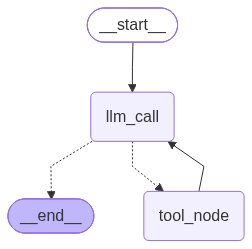

================================ Human Message =================================

Cuantos cvs tiene la honda rebel, busca nuevos modelos
================================== Ai Message ==================================

[{'id': 'toolu_014BRVCspjwkYnHo7Hun6gY8', 'caller': {'type': 'direct'}, 'input': {'query': 'Honda Rebel CV caballos de fuerza especificaciones', 'search_depth': 'advanced'}, 'name': 'tavily_search', 'type': 'tool_use', 'toolset_name': None}, {'id': 'toolu_01H8s3Z26fSmQzh8sBboETP8', 'caller': {'type': 'direct'}, 'input': {'query': 'Honda Rebel nuevos modelos 2025 2026', 'search_depth': 'advanced'}, 'name': 'tavily_search', 'type': 'tool_use', 'toolset_name': None}]
Tool Calls:
  tavily_search (toolu_014BRVCspjwkYnHo7Hun6gY8)
 Call ID: toolu_014BRVCspjwkYnHo7Hun6gY8
  Args:
    query: Honda Rebel CV caballos de fuerza especificaciones
    search_depth: advanced
  tavily_search (toolu_01H8s3Z26fSmQzh8sBboETP8)
 Call ID: toolu_01H8s3Z26fSmQzh8sBboETP8
  Args:
    query: Hond

In [2]:
from espadas_langgraph_websearchagent import searchagent

agent = searchagent.create_agent_with_search_tool()
result = searchagent.run_agent_with_search_tool(agent, "Cuantos cvs tiene la honda rebel, busca nuevos modelos")

In [ ]:
from langchain.messages import HumanMessage, ToolMessage

from espadas_langgraph_websearchagent.questions import QUESTIONS

correct = 0

for question, should_search in QUESTIONS:
    # Ask the agent
    result = agent.invoke({"messages": [HumanMessage(content=question)]})

    # Find the ToolMessage if there is one
    search = None
    for r in result["messages"]:
        if isinstance(r, ToolMessage):
            search = r.artifact

    # Did it search?
    searched = search is not None

    # Was it right?
    if searched == should_search:
        correct = correct + 1
        check = "OK"
    else:
        check = "WRONG"

    # Tokens
    usage = searchagent.get_token_usage(result)

    # Print the info
    print("==========================================")
    print("Question:", question)
    print("Expected:", should_search, "| Searched:", searched, "|", check)
    print("Total tokens:", usage["total_tokens"])
    print("ToolMessage tokens:", usage["tool_result_tokens"])

    # If it searched, print the Tavily results
    if searched:
        print()
        print("Search query:", search["query"])
        print("Response time:", search["response_time"], "s")

        for r in search["results"]:
            print()
            print("   Score:", round(r["score"], 2))
            print("   Title:", r["title"])
            print("   URL:", r["url"])
            print("   Snippet:", r["content"][:150], "...")

    print()

print("Correct answers:", correct, "/", len(QUESTIONS))

Question: ¿Dónde está la arteria aorta?
Expected: False | Searched: False | OK
Total tokens: 2733
ToolMessage tokens: 0

Question: ¿Quién escribió el Quijote?
Expected: False | Searched: False | OK
Total tokens: 2434
ToolMessage tokens: 0

Question: ¿Qué es la fotosíntesis?
Expected: False | Searched: False | OK
Total tokens: 2822
ToolMessage tokens: 0

Question: ¿Quién ganó el Mundial de 2022?
Expected: False | Searched: False | OK
Total tokens: 2447
ToolMessage tokens: 0

Question: ¿Quién ganó el Mundial de 2026?
Expected: True | Searched: False | WRONG
Total tokens: 2476
ToolMessage tokens: 0

Question: ¿Qué tiempo hace hoy en Sevilla?
Expected: True | Searched: False | WRONG
Total tokens: 2503
ToolMessage tokens: 0

Question: Noticias de hoy en la Comunidad de Madrid
Expected: True | Searched: True | OK
Total tokens: 8435
ToolMessage tokens: 3022

Search query: noticias hoy Comunidad de Madrid
Response time: 1.48 s

   Score: 0.81
   Title: Actualidad de la Comunidad de Madrid | Ma